# 📘 Machine Learning 2026/2027
## Laboratorio: Funzione di costo, rischio e discesa del gradiente  

**Docenti:** Danilo Croce, Giorgio Gambosi

---

## Obiettivi del laboratorio
- Capire cos’è una **funzione di costo (loss function)** e perché è importante.  
- Introdurre il concetto di **rischio** ed **empirical risk**.  
- Vedere in pratica come funziona la **discesa del gradiente (gradient descent)**.  
- Sperimentare su un **dataset semplice** e visualizzare i risultati.  

👉 Questo laboratorio ha l'obiettivo di comprendere i concetti fondamentali, introducendo gradualmente gli aspetti matematici e sperimentandoli attraverso esempi pratici.

---

## Rischio e funzione di costo

- Il nostro obiettivo è addestrare un algoritmo che faccia **previsioni corrette**.
- Per misurare **quanto sbaglia**, usiamo una **funzione di costo (*loss function*)**.
- La loss ci dice “quanto costa” una certa predizione (potenzialmente sbagliata) rispetto al valore corretto.

⚠️ Importante: diverse funzioni di costo possono portare a valutazioni molto diverse.  
La scelta della loss **dipende dal problema e dalle priorità** (ad esempio: meglio evitare falsi positivi o falsi negativi?).


## Rischio e minimizzazione

### Dalla funzione di costo al rischio

Dato un input $x$, un modello di apprendimento $f$ produce una previsione $f(x)$.

Per valutare la qualità della previsione, utilizziamo una **funzione di costo** (*loss function*):

$$
L(y,f(x))
$$

dove:

- $y$ è il valore corretto associato all'input $x$;
- $f(x)$ è la previsione prodotta dal modello;
- $L(y,f(x))$ misura il costo associato alla previsione.

Ad esempio, in un problema di regressione, possiamo utilizzare l'**errore quadratico**:

$$
L(y,f(x))=(y-f(x))^2
$$

La loss misura quindi la qualità di **una singola previsione**.

Tuttavia, il nostro obiettivo non è prevedere correttamente un singolo esempio, ma costruire un modello che produca buone previsioni **in media, anche su dati mai osservati**.

Per questo introduciamo il concetto di **rischio atteso**.

### La distribuzione dei dati

Supponiamo che gli esempi siano generati secondo una distribuzione di probabilità congiunta $p(x,y)$, che descrive come si distribuiscono gli input e i relativi valori corretti.

Possiamo immaginare la generazione di un esempio $(x,y)$ attraverso due passaggi:

1. Estraiamo un input $x$ secondo la distribuzione marginale $p(x)$.
2. Dato $x$, estraiamo il corrispondente valore $y$ secondo la distribuzione condizionata $p(y\mid x)$.

Le due distribuzioni sono legate dalla relazione:

$$
p(x,y)=p(x)\,p(y\mid x)
$$

**Non assumiamo che a uno stesso input $x$ corrisponda necessariamente sempre lo stesso valore $y$.**

Due osservazioni con lo stesso input potrebbero infatti avere valori corretti differenti a causa del rumore nelle misurazioni o di fattori non rappresentati nell'input.

La distribuzione $p(y\mid x)$ permette di descrivere questa incertezza.

### Definizione di rischio atteso

Per valutare complessivamente un modello, consideriamo il costo medio delle sue previsioni rispetto alla distribuzione dei dati.

Definiamo il **rischio atteso** (*expected risk*) come:

$$
R(f)=\mathbb{E}_{(x,y)\sim p(x,y)}[L(y,f(x))]
$$

Nel caso di variabili continue, indicando con $D_x$ e $D_y$ i rispettivi domini:

$$
R(f)=\int_{D_x}\int_{D_y}L(y,f(x))\,p(x,y)\,dy\,dx
$$

Nel caso di variabili discrete, gli integrali sono sostituiti da sommatorie.

Il rischio rappresenta quindi il **costo medio atteso delle previsioni**, considerando tutti i possibili esempi e pesandoli secondo la loro probabilità.

### Interpretazione intuitiva

Immaginiamo di ripetere moltissime volte il seguente esperimento:

1. Estraiamo casualmente un input $x$.
2. Osserviamo il corrispondente valore corretto $y$.
3. Calcoliamo la previsione $f(x)$.
4. Misuriamo il costo attraverso $L(y,f(x))$.

La media dei costi ottenuti, al crescere del numero di esperimenti indipendenti, tende al rischio atteso, supponendo che la loss abbia valore atteso finito.

### Minimizzazione del rischio atteso

L'obiettivo dell'apprendimento è individuare, all'interno di una famiglia $F$ di possibili modelli, quello che minimizza il rischio atteso:

$$
f^*=\arg\min_{f\in F}R(f)
$$

In altre parole, vogliamo trovare il modello che produce il **minor costo medio possibile** sui dati generati dalla distribuzione reale.

**Il problema è che, nella pratica, non conosciamo la distribuzione $p(x,y)$** e quindi non possiamo generalmente calcolare direttamente il rischio atteso.

Disponiamo invece di un insieme finito di esempi di addestramento. Vedremo come utilizzarlo per stimare il rischio attraverso il **rischio empirico** (*empirical risk*).


#### Esempio: prevedere la pioggia

Immaginiamo di voler prevedere la **possibilità di pioggia** durante la giornata, date le condizioni del cielo al mattino.  
- **Osservazioni possibili**: "sereno" (S), "nuvoloso" (N), "coperto" (C).  
- **Etichette reali**: "pioggia" (T) e "non pioggia" (F).  
- **Predizioni possibili**: "pioggia" (T) e "non pioggia" (F).  

La bontà delle previsioni dipende dalla **funzione di costo** $L:\{T,F\}^2 \mapsto \mathbb{R}$, che assegna un “peso” agli errori.

---

### 1. Funzioni di costo

**Caso 1 – Costi simmetrici ($L_1$)**
Sbagliare in un senso o nell’altro è ugualmente spiacevole:

| $y$/pred |  T   |  F   |
| :------: | :--: | :--: |
|     T    |  0   |  1   |
|     F    |  1   |  0   |

---

**Caso 2 – Costi asimmetrici ($L_2$)**
Bagnarsi è molto peggio che portare l’ombrello inutilmente:

| $y$/pred |  T   |  F   |
| :------: | :--: | :--: |
|     T    |  0   | 25   |
|     F    |  1   |  0   |

---

### 2. Distribuzione congiunta $p(x,y)$

| $x$/$y$ |  T   |  F   |
| :-----: | :--: | :--: |
|    S    | .05  | .20  |
|    N    | .20  | .30  |
|    C    | .20  | .05  |

---

### 3. Modelli predittivi


| $x$ | $$f_1(x)$$ | $$f_2(x)$$ |
|:---:|:--------:|:--------:|
| S   | F        | F        |
| N   | F        | T        |
| C   | T        | T        |


---


### 4. Rischio atteso

Poiché gli input e le etichette sono discreti, il rischio atteso di un classificatore $f$, rispetto alla funzione di costo $L$, è:

$$
R_L(f)=\sum_x\sum_y L(y,f(x))\,p(x,y)
$$

Il rischio è quindi una **media pesata dei costi**, dove ogni possibile coppia $(x,y)$ contribuisce in proporzione alla sua probabilità.

#### Calcolo di esempio: $f_1$ con $L_1$

- Per $x=S$, il modello predice $f_1(S)=F$:
  - Se $y=T$: costo $1$, probabilità $0.05$ → contributo $0.05$.
  - Se $y=F$: costo $0$, probabilità $0.20$ → contributo $0$.

- Per $x=N$, il modello predice $f_1(N)=F$:
  - Se $y=T$: costo $1$, probabilità $0.20$ → contributo $0.20$.
  - Se $y=F$: costo $0$, probabilità $0.30$ → contributo $0$.

- Per $x=C$, il modello predice $f_1(C)=T$:
  - Se $y=T$: costo $0$, probabilità $0.20$ → contributo $0$.
  - Se $y=F$: costo $1$, probabilità $0.05$ → contributo $0.05$.

Sommando tutti i contributi:

$$
R_{L_1}(f_1)=0.05+0.20+0.05=0.30
$$

#### Risultati riassuntivi

| Classificatore | Costi simmetrici $L_1$ | Costi asimmetrici $L_2$ |
|:---:|---:|---:|
| $f_1$ | 0.30 | 6.30 |
| $f_2$ | 0.40 | 1.60 |

Con i **costi simmetrici**, il rischio minore è quello di $f_1$.

Con i **costi asimmetrici**, il rischio minore è quello di $f_2$.

La distribuzione dei dati e i classificatori sono rimasti invariati: abbiamo cambiato soltanto il modo in cui valutiamo gli errori.

**Il modello preferibile dipende quindi dalla funzione di costo e non soltanto dal numero di predizioni corrette.**


---

### 5. Conclusione

La **scelta del modello migliore** dipende da:  
1. **come pesiamo gli errori** (funzione di costo $L$),  
2. **come sono distribuiti i dati** ($p(x,y)$).  

Se cambiano i pesi o le probabilità, la decisione può ribaltarsi.


### Rischio atteso e rischio empirico

Il rischio atteso $R(f)$ misura il costo medio delle previsioni rispetto alla distribuzione reale dei dati $p(x,y)$.

Nella pratica, però, **questa distribuzione non è conosciuta** e non possiamo quindi calcolare direttamente il rischio atteso.

Disponiamo invece di un insieme finito di esempi di addestramento:

$$
D=\{(x_1,y_1),\ldots,(x_n,y_n)\}
$$

Supponiamo che questi esempi siano estratti in modo indipendente dalla stessa distribuzione $p(x,y)$.

Per stimare il rischio atteso di un modello possiamo calcolare la media delle perdite sugli esempi disponibili.

Definiamo così il **rischio empirico** (*empirical risk*):

$$
\hat R(f;D)=\frac{1}{n}\sum_{i=1}^{n}L(y_i,f(x_i))
$$

L'obiettivo dell'**Empirical Risk Minimization (ERM)** è individuare il modello che minimizza il rischio empirico:

$$
\hat f=\arg\min_{f\in F}\hat R(f;D)
$$

In altre parole:

1. Valutiamo quanto ogni modello sbaglia sugli esempi disponibili.
2. Calcoliamo la media dei costi.
3. Scegliamo il modello che produce il costo medio più basso.

### Rischio empirico e generalizzazione

**Minimizzare il rischio empirico non garantisce necessariamente di minimizzare il rischio atteso.**

Un modello potrebbe adattarsi molto bene agli esempi di addestramento, ma produrre previsioni poco accurate su dati mai osservati.

Questo è il problema della **generalizzazione**.

La relazione tra rischio empirico e rischio atteso dipende da diversi fattori:

- **Numero di esempi ($n$):** per un modello fissato, se gli esempi sono indipendenti e identicamente distribuiti e la loss ha valore atteso finito, il rischio empirico converge al rischio atteso al crescere del numero di osservazioni.
- **Distribuzione dei dati:** la variabilità delle osservazioni influenza la precisione della stima.
- **Funzione di costo:** perdite molto elevate o variabili possono rendere più difficile ottenere stime accurate.
- **Famiglia di modelli ($F$):** una famiglia troppo flessibile può adattarsi eccessivamente ai dati di training, mentre una famiglia troppo limitata potrebbe non contenere modelli sufficientemente adeguati.

**Attenzione:** stimare il rischio di un modello fissato e scegliere un modello minimizzando il rischio sugli stessi dati sono due problemi differenti.

Un rischio empirico basso non garantisce quindi un rischio atteso basso.

Riprenderemo questi aspetti quando studieremo la generalizzazione e l'overfitting.



### Minimizzazione del rischio empirico e modelli parametrici

In molti problemi di Machine Learning, i modelli appartengono a una famiglia di funzioni descritta attraverso un insieme di parametri.

Possiamo scrivere:

$$
F=\{f(\mathbf{x};\theta)\mid\theta\in D_\theta\}
$$

dove:

- $\theta$ è il vettore dei parametri del modello;
- $D_\theta$ è l'insieme dei possibili valori dei parametri;
- ogni scelta di $\theta$ identifica una particolare funzione della famiglia $F$.

### Esempio: regressione lineare

Vogliamo prevedere una variabile $y\in\mathbb{R}$ a partire da $m$ caratteristiche:

$$
\mathbf{x}=(x_1,\ldots,x_m)
$$

Consideriamo una famiglia di modelli lineari nei parametri:

$$
f(\mathbf{x};\mathbf{w})=w_0+w_1x_1+\ldots+w_mx_m
$$

dove $\mathbf{w}=(w_0,\ldots,w_m)$ contiene i coefficienti del modello, incluso il termine noto $w_0$.

### Il rischio empirico come funzione dei parametri

Per una famiglia parametrica, il rischio empirico può essere scritto come:

$$
\hat R(\theta;D)=\frac{1}{n}\sum_{i=1}^{n}L(y_i,f(\mathbf{x}_i;\theta))
$$

L'apprendimento consiste nel trovare i parametri che minimizzano questa funzione:

$$
\hat\theta=\arg\min_{\theta\in D_\theta}\hat R(\theta;D)
$$

Il modello appreso sarà quindi:

$$
\hat f(\mathbf{x})=f(\mathbf{x};\hat\theta)
$$

In altre parole:

1. Scegliamo una famiglia di modelli $F$.
2. Valutiamo il rischio empirico per ogni possibile scelta dei parametri.
3. Cerchiamo i parametri che rendono minimo il costo medio.

Il metodo utilizzato per trovare questi parametri dipende dal problema: possiamo utilizzare soluzioni analitiche oppure algoritmi numerici di ottimizzazione, come la **discesa del gradiente**.



### Ricerca analitica dell'ottimo: dalle derivate al gradiente

Supponiamo di voler minimizzare una funzione di rischio empirico $\hat R(\theta;D)$, differenziabile rispetto ai parametri, senza vincoli e con $\theta\in\mathbb{R}^d$.

#### Partiamo da una funzione di una sola variabile

Consideriamo una funzione $g(\theta)$.

La sua **derivata** $g'(\theta)$ descrive come cambia localmente il valore della funzione quando modifichiamo leggermente $\theta$:

- Se $g'(\theta)>0$, la funzione cresce quando aumentiamo $\theta$.
- Se $g'(\theta)<0$, la funzione decresce quando aumentiamo $\theta$.
- Se $g'(\theta)=0$, la funzione è localmente stazionaria: potrebbe trovarsi in un minimo, in un massimo o in un altro punto stazionario.

Ad esempio, per

$$
g(\theta)=(\theta-2)^2
$$

abbiamo:

$$
g'(\theta)=2(\theta-2)
$$

La derivata si annulla in $\theta=2$, che in questo caso è il minimo della funzione.

#### E se la funzione dipende da più variabili?

Nel Machine Learning, il rischio empirico dipende generalmente da molti parametri:

$$
\hat R(\theta_1,\theta_2,\ldots,\theta_d;D)
$$

Non abbiamo più una sola derivata, perché possiamo modificare ciascun parametro indipendentemente dagli altri.

Per questo utilizziamo le **derivate parziali**:

$$
\frac{\partial \hat R}{\partial \theta_j}
$$

La derivata parziale rispetto a $\theta_j$ misura come cambia localmente il rischio quando modifichiamo $\theta_j$, mantenendo fissi gli altri parametri.

Possiamo raccogliere tutte le derivate parziali in un unico vettore, chiamato **gradiente**:

$$
\nabla_\theta\hat R(\theta;D)=
\begin{bmatrix}
\frac{\partial\hat R}{\partial\theta_1}\\
\vdots\\
\frac{\partial\hat R}{\partial\theta_d}
\end{bmatrix}
$$

**Il gradiente ci dice quindi come varia localmente la funzione rispetto a tutti i suoi parametri.**

Più precisamente, rispetto alla norma euclidea, il gradiente indica la direzione di massima crescita locale della funzione, mentre la direzione opposta, $-\nabla_\theta\hat R$, indica quella di massima diminuzione locale, quando il gradiente è diverso da zero.

#### Come cerchiamo un minimo?

Per una funzione differenziabile di una variabile, cerchiamo i punti in cui la derivata si annulla.

Con più variabili, applichiamo lo stesso principio: cerchiamo i punti in cui **tutte le derivate parziali sono nulle**.

$$
\frac{\partial\hat R(\theta;D)}{\partial\theta_j}=0
\qquad j=1,\ldots,d
$$

Otteniamo così un sistema di $d$ equazioni nelle $d$ incognite che costituiscono il vettore $\theta$.

Utilizzando il gradiente, possiamo scrivere questa condizione in forma compatta:

$$
\nabla_\theta\hat R(\theta;D)=\mathbf{0}
$$

**Attenzione:** un gradiente nullo è una condizione necessaria per un minimo locale interno di una funzione differenziabile, ma non sufficiente. Un punto stazionario può essere un minimo, un massimo oppure un punto di sella.

#### Perché non risolviamo sempre questo sistema?

In molti problemi di Machine Learning:

- Il sistema delle derivate può essere troppo complesso per essere risolto analiticamente.
- Il numero di parametri può essere molto elevato.
- Anche trovando un punto stazionario, non è detto che sia un minimo.

Per queste ragioni ricorriamo spesso a **metodi numerici di ottimizzazione**, come il **Gradient Descent**.

L'idea sarà semplice: invece di risolvere direttamente il sistema $\nabla_\theta\hat R=\mathbf{0}$, utilizzeremo il gradiente per individuare, a ogni iterazione, una direzione lungo cui cercare di ridurre il rischio empirico.



## Gradient Descent

La **discesa del gradiente** (*Gradient Descent*) è un metodo numerico iterativo per minimizzare una funzione differenziabile.

Invece di cercare direttamente una soluzione analitica, partiamo da un valore iniziale dei parametri e li aggiorniamo progressivamente:

$$
\theta^{(k+1)}
=
\theta^{(k)}-\eta\nabla_\theta\hat R(\theta^{(k)})
$$

dove:

- $\theta^{(k)}$ rappresenta i parametri all'iterazione $k$;
- $\nabla_\theta\hat R(\theta^{(k)})$ è il gradiente del rischio empirico, calcolato nei parametri correnti;
- $\eta>0$ è il **learning rate**, che controlla l'ampiezza dell'aggiornamento.

Come abbiamo visto, il gradiente descrive come varia localmente una funzione rispetto ai suoi parametri.

Il Gradient Descent sfrutta questa informazione per aggiornare iterativamente i parametri nella **direzione opposta al gradiente**, cercando così di ridurre il valore della funzione obiettivo.

### Intuizione

Immaginiamo di trovarci su una collina e voler raggiungere il punto più basso.

- Il **gradiente** indica la direzione in cui la salita è più ripida.
- Muovendoci nella **direzione opposta**, cerchiamo di scendere.
- Il **learning rate** controlla quanto ci spostiamo lungo questa direzione.

Se il passo è troppo piccolo, la discesa può risultare lenta.

Se è troppo grande, possiamo oltrepassare il minimo o addirittura aumentare il valore della funzione.

La lunghezza effettiva dello spostamento dipende sia dal learning rate sia dalla grandezza del gradiente.

**La convergenza non è garantita in generale:** dipende dalle proprietà della funzione da minimizzare e dalla scelta del learning rate.

Il Gradient Descent è un **metodo del primo ordine**, perché utilizza le derivate prime della funzione obiettivo.


---


### Esempio: gradiente di un paraboloide

Consideriamo la funzione:

$$
g(x,y)=x^2+y^2
$$

La sua superficie è un **paraboloide**, simile a una ciotola, con minimo nell'origine $(0,0)$.

#### Calcolo del gradiente

Le derivate parziali sono:

$$
\frac{\partial g}{\partial x}=2x,
\qquad
\frac{\partial g}{\partial y}=2y
$$

Il gradiente è quindi:

$$
\nabla g(x,y)=
\begin{bmatrix}
2x\\
2y
\end{bmatrix}
$$

Scegliamo il punto $(1,2)$:

$$
\nabla g(1,2)=
\begin{bmatrix}
2\\
4
\end{bmatrix}
$$

Questo vettore indica la direzione di massima crescita locale della funzione nel piano $(x,y)$.

Per minimizzare la funzione ci muoviamo invece nella direzione opposta:

$$
-\nabla g(1,2)=
\begin{bmatrix}
-2\\
-4
\end{bmatrix}
$$

#### Un passo di Gradient Descent

Partendo da $(1,2)$, la regola di aggiornamento è:

$$
\begin{bmatrix}
x_{\text{nuovo}}\\
y_{\text{nuovo}}
\end{bmatrix}
=
\begin{bmatrix}
1\\
2
\end{bmatrix}
-
\eta
\begin{bmatrix}
2\\
4
\end{bmatrix}
$$

Con un learning rate $\eta=0.1$ otteniamo:

$$
(x_{\text{nuovo}},y_{\text{nuovo}})=(0.8,1.6)
$$

Il valore della funzione diminuisce:

$$
g(1,2)=5
$$

$$
g(0.8,1.6)=3.2
$$

Abbiamo quindi effettuato **un passo che riduce il valore della funzione obiettivo**.


Nel grafico tridimensionale rappresentiamo la superficie del paraboloide, il punto iniziale e quello raggiunto dopo un aggiornamento di Gradient Descent.

La freccia collega i due punti nello spazio tridimensionale, visualizzando la variazione delle coordinate e la diminuzione del valore della funzione.

**Attenzione:** il Gradient Descent aggiorna le variabili $(x,y)$ nella direzione opposta al gradiente $-\nabla g(x,y)$. La freccia tridimensionale rappresenta il risultato dell'aggiornamento, non direttamente il vettore gradiente.


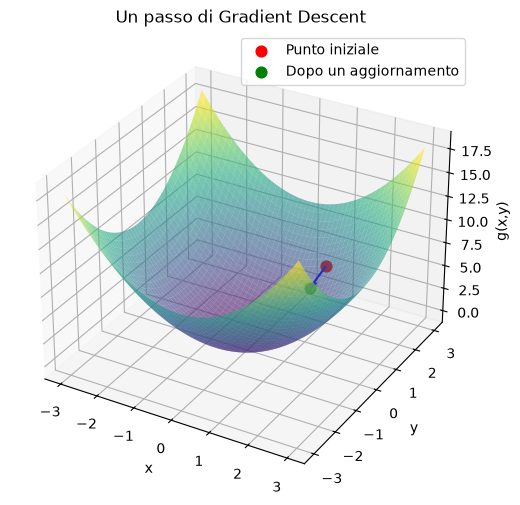

Valore iniziale: 5.00
Valore dopo il passo: 3.20


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Funzione da minimizzare
def g(x, y):
    return x**2 + y**2

# Gradiente
def grad_g(x, y):
    return np.array([2*x, 2*y])

# Superficie
x = np.linspace(-3, 3, 50)
y = np.linspace(-3, 3, 50)
X_grid, Y_grid = np.meshgrid(x, y)
Z_grid = g(X_grid, Y_grid)

# Punto iniziale
x0, y0 = 1, 2
z0 = g(x0, y0)
grad = grad_g(x0, y0)

# Un passo di discesa
eta = 0.1
x1, y1 = np.array([x0, y0]) - eta * grad
z1 = g(x1, y1)

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(
    X_grid, Y_grid, Z_grid,
    cmap='viridis', alpha=0.6
)

ax.scatter(x0, y0, z0, color='red',
           s=60, label='Punto iniziale')

ax.scatter(x1, y1, z1, color='green',
           s=60, label='Dopo un aggiornamento')

# Spostamento tridimensionale tra i due punti sulla superficie
ax.quiver(
    x0, y0, z0,
    x1-x0, y1-y0, z1-z0,
    color='blue',
    arrow_length_ratio=0.2
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('g(x,y)')
ax.set_title('Un passo di Gradient Descent')
ax.legend()

plt.show()

print(f"Valore iniziale: {z0:.2f}")
print(f"Valore dopo il passo: {z1:.2f}")



### Dal gradiente di una funzione al Machine Learning

Nell'esempio precedente abbiamo utilizzato il gradiente per minimizzare una semplice funzione matematica.

Nel Machine Learning vogliamo applicare lo stesso principio al **rischio empirico**, che dipende dai parametri del modello:

$$
\hat R(\theta)=\frac{1}{n}\sum_{i=1}^{n}L(y_i,f(\mathbf{x}_i;\theta))
$$

Quando la funzione di costo è differenziabile rispetto ai parametri, possiamo calcolare:

$$
\nabla_\theta\hat R(\theta)
=
\frac{1}{n}\sum_{i=1}^{n}
\nabla_\theta L(y_i,f(\mathbf{x}_i;\theta))
$$

Il gradiente del rischio empirico è quindi la **media dei gradienti delle perdite sui singoli esempi**.

Questa proprietà suggerisce tre strategie di ottimizzazione:

- **Batch Gradient Descent:** usa tutti gli esempi a ogni aggiornamento.
- **Stochastic Gradient Descent:** usa un solo esempio a ogni aggiornamento.
- **Mini-Batch Gradient Descent:** usa un gruppo di esempi a ogni aggiornamento.

La differenza principale è quindi **quanti esempi vengono utilizzati per calcolare ciascun aggiornamento**.

Vediamo queste strategie applicate allo stesso problema di classificazione.



## Let's work: un esempio di classificazione binaria

Applichiamo il Gradient Descent a un problema di **classificazione binaria**, in cui ogni esempio è descritto da due caratteristiche $(x_1,x_2)$ e da un'etichetta $t\in\{0,1\}$.

Vogliamo costruire un modello che stimi la probabilità di appartenenza alla classe positiva.

**Una piccola anticipazione:** utilizzeremo un modello chiamato **Logistic Regression**, che studieremo formalmente più avanti nel corso. Per ora ci interessa usarlo per comprendere come si definisce una funzione di costo, come se ne calcola il gradiente e come si apprendono i parametri attraverso il Gradient Descent.

### Il modello

Partiamo da una combinazione lineare delle caratteristiche:

$$
z=\theta_0+\theta_1x_1+\theta_2x_2
$$

dove $\theta_0$ è il termine noto (*bias*) e $\theta_1,\theta_2$ sono i pesi delle caratteristiche.

Applichiamo a $z$ la **funzione sigmoide**:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

La previsione del modello è:

$$
f(\mathbf{x};\theta)=\sigma(z)
=P(t=1\mid\mathbf{x};\theta)
$$

Interpretiamo quindi l'output come la probabilità stimata di appartenenza alla classe positiva.

### Perché si chiama Logistic Regression se stiamo facendo classificazione?

Il termine *regression* è legato alla formulazione statistica del modello, che descrive una relazione parametrica tra le caratteristiche e la probabilità della classe positiva.

Più precisamente, la relazione lineare riguarda il **logaritmo del rapporto tra le probabilità delle due classi** (*log-odds*):

$$
\log\frac{p}{1-p}
=
\theta_0+\theta_1x_1+\theta_2x_2
$$

dove $p=f(\mathbf{x};\theta)$.

La sigmoide permette di ottenere la probabilità $p$, che può essere successivamente trasformata in una decisione di classificazione mediante una soglia.

Il modello **stima una probabilità continua**, mentre la decisione finale assegna una **classe discreta**.

Approfondiremo questa formulazione nelle prossime lezioni.

### La funzione di costo: Binary Cross-Entropy

Per valutare le predizioni utilizziamo la **Binary Cross-Entropy**:

$$
L(t,f(\mathbf{x};\theta))
=
-\left[
t\log f(\mathbf{x};\theta)
+
(1-t)\log(1-f(\mathbf{x};\theta))
\right]
$$

dove $t\in\{0,1\}$ è l'etichetta reale.

- Se $t=1$, il costo cresce quando il modello assegna una probabilità bassa alla classe positiva.
- Se $t=0$, il costo cresce quando il modello assegna una probabilità alta alla classe positiva.

La Binary Cross-Entropy penalizza particolarmente le previsioni molto sicure ma sbagliate.

#### Due esempi numerici

**Esempio 1: la classe corretta è $t=1$**

In questo caso:

$$
L(1,f)=-\log(f)
$$

Se il modello assegna una probabilità elevata alla classe corretta:

$$
L(1,0.9)=-\log(0.9)\approx 0.105
$$

Se invece assegna una probabilità molto bassa:

$$
L(1,0.1)=-\log(0.1)\approx 2.303
$$

La seconda previsione riceve una penalizzazione molto maggiore.

**Esempio 2: la classe corretta è $t=0$**

In questo caso:

$$
L(0,f)=-\log(1-f)
$$

Se il modello assegna una probabilità bassa alla classe positiva:

$$
L(0,0.1)=-\log(0.9)\approx 0.105
$$

Se invece le assegna una probabilità elevata:

$$
L(0,0.9)=-\log(0.1)\approx 2.303
$$

I ruoli si invertono perché ora la classe corretta è quella negativa.

**Osservazione:** la Binary Cross-Entropy è non negativa, tende a zero quando la probabilità assegnata alla classe corretta tende a 1 e cresce senza limite quando tale probabilità tende a 0.

### Rappresentazione vettoriale e bias

Per semplificare la notazione, aggiungiamo a ogni esempio una caratteristica costante $x_{i0}=1$.

Definiamo:

$$
\mathbf{x}_i=
\begin{bmatrix}
1\\
x_{i1}\\
x_{i2}
\end{bmatrix}
\qquad
\theta=
\begin{bmatrix}
\theta_0\\
\theta_1\\
\theta_2
\end{bmatrix}
$$

Possiamo così scrivere:

$$
z_i=\theta^\top\mathbf{x}_i
$$

$$
f_i=f(\mathbf{x}_i;\theta)=\sigma(z_i)
$$

Il bias viene quindi trattato come un parametro del modello, al pari degli altri pesi.

### Rischio empirico

Su un dataset di $n$ osservazioni, il rischio empirico è la media delle Binary Cross-Entropy:

$$
\hat R(\theta)
=
-\frac{1}{n}\sum_{i=1}^{n}
\left[
t_i\log f_i+(1-t_i)\log(1-f_i)
\right]
$$

Vogliamo trovare:

$$
\hat\theta=\arg\min_\theta\hat R(\theta)
$$

Per applicare il Gradient Descent dobbiamo quindi calcolare il gradiente del rischio rispetto ai parametri.

### Derivazione del gradiente: partiamo da un singolo esempio

Consideriamo inizialmente la loss di un solo esempio $i$:

$$
L_i=-\left[t_i\log f_i+(1-t_i)\log(1-f_i)\right]
$$

Vogliamo calcolare la sua derivata rispetto a un generico parametro $\theta_j$.

Osserviamo la dipendenza tra le quantità:

$$
\boxed{
\theta_j
\longrightarrow
z_i
\longrightarrow
f_i
\longrightarrow
L_i
}
$$

Modificando $\theta_j$, cambia la combinazione lineare $z_i$; di conseguenza cambiano la probabilità $f_i$ e la loss $L_i$.

Per calcolare questo effetto utilizziamo la **regola della catena** (*chain rule*):

$$
\frac{\partial L_i}{\partial\theta_j}
=
\underbrace{\frac{\partial L_i}{\partial f_i}}_{\text{loss}}
\cdot
\underbrace{\frac{\partial f_i}{\partial z_i}}_{\text{sigmoide}}
\cdot
\underbrace{\frac{\partial z_i}{\partial\theta_j}}_{\text{modello lineare}}
$$

Calcoliamo i tre termini separatamente.

#### Passaggio 1: derivata della loss

Deriviamo la Binary Cross-Entropy rispetto alla probabilità $f_i$, considerando $t_i$ costante:

$$
\frac{\partial L_i}{\partial f_i}
=
-\frac{t_i}{f_i}
+
\frac{1-t_i}{1-f_i}
$$

Abbiamo utilizzato la derivata del logaritmo:

$$
\frac{d}{du}\log u=\frac{1}{u}
$$

Nel secondo termine compare un segno positivo perché la derivata di $1-f_i$ rispetto a $f_i$ è $-1$.

#### Passaggio 2: derivata della sigmoide

Poiché:

$$
f_i=\sigma(z_i)=\frac{1}{1+e^{-z_i}}
$$

e:

$$
\sigma'(z)=\sigma(z)(1-\sigma(z))
$$

otteniamo:

$$
\frac{\partial f_i}{\partial z_i}
=
f_i(1-f_i)
$$

#### Passaggio 3: derivata della combinazione lineare

Scriviamo:

$$
z_i=\sum_{k=0}^{2}\theta_kx_{ik}
$$

Derivando rispetto a $\theta_j$, gli altri parametri rimangono costanti:

$$
\frac{\partial z_i}{\partial\theta_j}=x_{ij}
$$

La formula vale anche per il bias, perché $x_{i0}=1$.

#### Applichiamo la regola della catena

Sostituendo i tre risultati:

$$
\frac{\partial L_i}{\partial\theta_j}
=
\left[
-\frac{t_i}{f_i}
+
\frac{1-t_i}{1-f_i}
\right]
f_i(1-f_i)x_{ij}
$$

Semplifichiamo:

$$
=
\left[
-t_i(1-f_i)+(1-t_i)f_i
\right]x_{ij}
$$

Sviluppando le parentesi:

$$
=
\left[
-t_i+t_if_i+f_i-t_if_i
\right]x_{ij}
$$

I termini $t_if_i$ si cancellano e otteniamo:

$$
\boxed{
\frac{\partial L_i}{\partial\theta_j}
=
(f_i-t_i)x_{ij}
}
$$

**Questo è il risultato fondamentale:** la derivata della loss rispetto a un parametro è data dalla differenza tra probabilità predetta e target, moltiplicata per la caratteristica corrispondente.

### Dal singolo esempio al rischio empirico

Il rischio empirico è la media delle loss:

$$
\hat R(\theta)=\frac{1}{n}\sum_{i=1}^{n}L_i
$$

La derivata di una media è la media delle derivate:

$$
\frac{\partial\hat R}{\partial\theta_j}
=
\frac{1}{n}\sum_{i=1}^{n}
\frac{\partial L_i}{\partial\theta_j}
$$

Sostituendo il risultato appena ottenuto:

$$
\boxed{
\frac{\partial\hat R}{\partial\theta_j}
=
\frac{1}{n}\sum_{i=1}^{n}(f_i-t_i)x_{ij}
}
$$

Ogni esempio contribuisce quindi alla derivata attraverso il proprio errore di predizione, pesato dalla caratteristica $x_{ij}$.

### Gradiente completo

Il gradiente raccoglie le derivate rispetto ai tre parametri:

$$
\nabla_\theta\hat R(\theta)
=
\begin{bmatrix}
\frac{\partial\hat R}{\partial\theta_0}\\
\frac{\partial\hat R}{\partial\theta_1}\\
\frac{\partial\hat R}{\partial\theta_2}
\end{bmatrix}
$$

Utilizzando il vettore delle caratteristiche $\mathbf{x}_i$, possiamo scrivere:

$$
\boxed{
\nabla_\theta\hat R(\theta)
=
\frac{1}{n}\sum_{i=1}^{n}
(f_i-t_i)\mathbf{x}_i
}
$$

Il gradiente del rischio empirico è dunque la **media dei vettori gradiente delle singole loss**.

### Forma matriciale

Per implementare il calcolo con NumPy utilizziamo una rappresentazione matriciale.

Definiamo:

- $X\in\mathbb{R}^{n\times d}$: matrice dei dati, inclusa la colonna di bias; nel nostro esempio $d=3$;
- $t\in\mathbb{R}^{n\times 1}$: vettore delle etichette;
- $f(\theta,X)\in\mathbb{R}^{n\times 1}$: vettore delle probabilità predette.

La matrice dei dati è:

$$
X=
\begin{bmatrix}
1 & x_{11} & x_{12}\\
1 & x_{21} & x_{22}\\
\vdots & \vdots & \vdots\\
1 & x_{n1} & x_{n2}
\end{bmatrix}
$$

Il vettore delle differenze tra predizioni e target è:

$$
f(\theta,X)-t
=
\begin{bmatrix}
f_1-t_1\\
f_2-t_2\\
\vdots\\
f_n-t_n
\end{bmatrix}
$$

Moltiplicando $X^\top$ per questo vettore:

$$
X^\top(f(\theta,X)-t)
=
\begin{bmatrix}
\sum_{i=1}^{n}(f_i-t_i)\\
\sum_{i=1}^{n}(f_i-t_i)x_{i1}\\
\sum_{i=1}^{n}(f_i-t_i)x_{i2}
\end{bmatrix}
$$

Ritroviamo esattamente le tre componenti del gradiente.

Pertanto:

$$
\boxed{
\nabla_\theta\hat R(\theta)
=
\frac{1}{n}X^\top(f(\theta,X)-t)
}
$$

La forma matriciale è equivalente alla sommatoria, ma permette di calcolare tutte le componenti del gradiente attraverso un'unica operazione.

### Aggiornamento con Gradient Descent

La regola generale è:

$$
\theta^{(k+1)}
=
\theta^{(k)}-\eta\nabla_\theta\hat R(\theta^{(k)})
$$

Sostituendo il gradiente della Binary Cross-Entropy:

$$
\boxed{
\theta^{(k+1)}
=
\theta^{(k)}
+
\frac{\eta}{n}X^\top
(t-f(\theta^{(k)},X))
}
$$

**Questa è la formula che implementeremo nel codice.**

A ogni iterazione calcoleremo le predizioni, determineremo il gradiente e aggiorneremo i parametri per cercare di ridurre il rischio empirico.

La struttura del modello rimane invariata: **sono i parametri $\theta$ a essere appresi dai dati**.

Vedremo ora come realizzare questi aggiornamenti utilizzando **Batch Gradient Descent, Stochastic Gradient Descent e Mini-Batch Gradient Descent**.


## Caricamento delle librerie

Qui importiamo alcune librerie fondamentali:
- **NumPy, Pandas** → per la gestione e manipolazione dei dati
- **Matplotlib** → per produrre grafici
- **SciPy** → per funzioni matematiche avanzate
- **time** → per misurare i tempi di esecuzione

Molte di queste librerie sono già presenti in Colab, mentre in locale potrebbero dover essere installate (ad esempio con `conda install` o `pip install`).

In [2]:
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scipy.special as sp
import pandas as pd

import time


#### Scaricare i dati

Per lavorare su un problema pratico dobbiamo prima scaricare il dataset `testSet.txt`.

In Google Colab, il simbolo `!` permette di eseguire un **comando di shell** direttamente dal notebook.

Utilizziamo il comando `wget` per scaricare il file da Internet, specificando due opzioni:

- **`-q`** (*quiet*): esegue il download senza mostrare i normali messaggi di avanzamento.
- **`-O testSet.txt`** (*output document*): salva il contenuto scaricato nel file `testSet.txt`, sovrascrivendolo se esiste già.

In questo modo possiamo eseguire più volte la cella senza creare copie del dataset con nomi differenti.

**Attenzione:** `-O` è maiuscola. L'opzione `-o` minuscola ha un significato diverso: serve a salvare i messaggi di `wget` in un file di log.


In [3]:
!wget -q -O testSet.txt https://tvml.github.io/ml2425/dataset/testSet.txt

Prima di procedere con la costruzione del modello, è utile dare uno sguardo al dataset su cui lavoreremo.  
Il file `testSet.txt` contiene tre colonne:  
- **x1** e **x2**: le due caratteristiche (coordinate) che descrivono ogni punto;  
- **t**: l’etichetta della classe, che può assumere valore 0 o 1.  

Nelle prossime celle mostriamo alcune righe del dataset e la distribuzione delle classi, così da avere un’idea più concreta dei dati su cui applicheremo la discesa del gradiente.

In [4]:
# Carichiamo il dataset (già scaricato con wget)
data = pd.read_csv(
    "testSet.txt",
    sep=r"\s+",
    header=None,
    names=["x1", "x2", "t"]
)

# Visualizziamo le prime osservazioni
print("Esempi dal dataset:")
display(data.head())

# Controlliamo anche la distribuzione delle classi
print("\nDistribuzione delle etichette:")
display(data['t'].value_counts())

Esempi dal dataset:


,x1,x2,t
0,-0.017612,14.053064,0
1,-1.395634,4.662541,1
2,-0.752157,6.538620,0
3,-1.322371,7.152853,0
4,0.423363,11.054677,0



Distribuzione delle etichette:


t
1    53
0    47
Name: count, dtype: int64

#### Funzioni di visualizzazione

Per comprendere il comportamento degli algoritmi di ottimizzazione, definiamo alcune funzioni di supporto che permettono di:

- Visualizzare il dataset e la frontiera decisionale del modello.
- Tracciare l'andamento del rischio empirico durante l'addestramento.
- Osservare come evolvono i parametri $\theta_0,\theta_1,\theta_2$ durante il Gradient Descent.

Le visualizzazioni permettono di distinguere due aspetti: **l'evoluzione dei parametri nello spazio del modello** e **l'effetto di questi parametri sulla frontiera decisionale nello spazio delle caratteristiche**.

In [5]:
plt.style.use('ggplot')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['image.cmap'] = 'jet'
plt.rcParams['image.interpolation'] = 'none'
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 8

In [6]:

def plot_ds(data, theta=None):
    """
    Visualizza il dataset e, se theta è specificato,
    la frontiera decisionale del modello.

    La frontiera è definita da:
        theta_0 + theta_1*x1 + theta_2*x2 = 0
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    for label in [0, 1]:
        subset = data[data.t == label]
        ax.scatter(
            subset.x1, subset.x2,
            label=f"Classe {label}",
            edgecolor="k", alpha=0.7
        )

    if theta is not None:
        theta = np.asarray(theta).ravel()

        if abs(theta[2]) > 1e-12:
            x1 = np.linspace(
                data.x1.min(), data.x1.max(), 200
            )
            x2 = -(theta[0] + theta[1]*x1) / theta[2]
            ax.plot(x1, x2, label="Frontiera decisionale")

        elif abs(theta[1]) > 1e-12:
            ax.axvline(
                -theta[0] / theta[1],
                label="Frontiera decisionale"
            )

    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title("Dataset e frontiera decisionale")
    ax.legend()
    plt.show()

In [7]:

def plot_all(cost_history, theta_history, steps=None):
    """
    Visualizza:
    1. L'andamento del rischio empirico.
    2. L'evoluzione dei parametri theta_0, theta_1, theta_2.

    steps specifica gli aggiornamenti a cui sono stati
    registrati i valori, utile per SGD.
    """
    costs = np.asarray(cost_history).ravel()
    thetas = np.asarray(theta_history)

    if steps is None:
        steps = np.arange(1, len(costs) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    axes[0].plot(steps, costs)
    axes[0].set_xlabel("Aggiornamenti dei parametri")
    axes[0].set_ylabel("Rischio empirico")
    axes[0].set_title("Andamento della loss")

    for j in range(thetas.shape[1]):
        axes[1].plot(
            steps,
            thetas[:, j],
            label=fr"$\theta_{j}$"
        )

    axes[1].set_xlabel("Aggiornamenti dei parametri")
    axes[1].set_ylabel("Valore del parametro")
    axes[1].set_title("Evoluzione dei parametri del modello")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

Per visualizzare meglio la natura del problema, rappresentiamo i punti del dataset nel piano delle caratteristiche $(x_1, x_2)$.  
Ogni punto è colorato in base alla sua etichetta $t$:  
- un colore per la **classe 0**  
- un colore diverso per la **classe 1**  

In questo modo possiamo osservare come i dati siano distribuiti e intuire la possibilità di separarli mediante una retta.

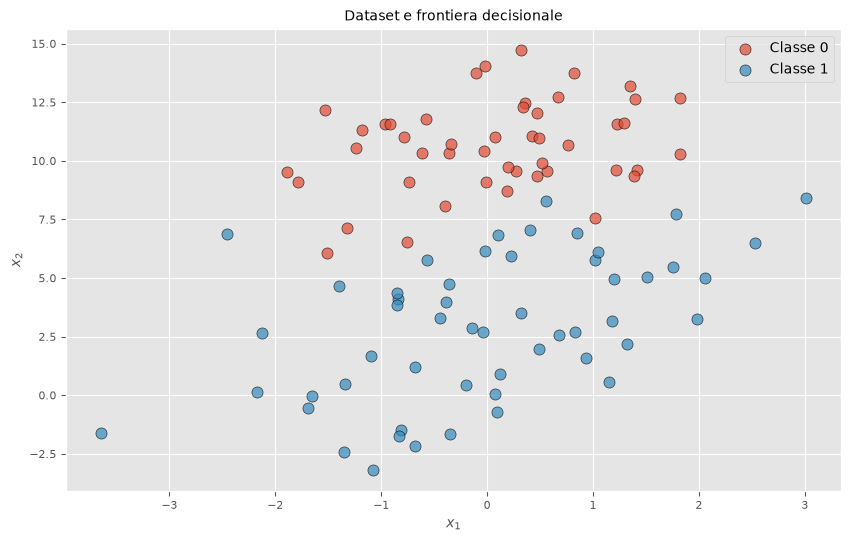

In [8]:
plot_ds(data)


### 📌 Mettiamo insieme i concetti

Prima di passare all'implementazione, è utile distinguere tre oggetti fondamentali.

**1. Il modello: cosa vogliamo apprendere?**

$$
f(\mathbf{x};\theta)
$$

È la funzione che, dato un input $\mathbf{x}$, produce una predizione. La sua struttura è definita dalla famiglia di modelli scelta, mentre i parametri $\theta$ devono essere appresi dai dati.

**2. La loss: come valutiamo una predizione?**

$$
L(y,f(\mathbf{x};\theta))
$$

Misura il costo associato alla predizione del modello rispetto al valore corretto $y$, su un singolo esempio.

**3. Il rischio empirico: cosa vogliamo minimizzare?**

$$
\hat R(\theta;D)
=
\frac{1}{n}\sum_{i=1}^{n}
L(y_i,f(\mathbf{x}_i;\theta))
$$

È la media delle loss sugli esempi di training. Una volta fissati il dataset e la famiglia di modelli, diventa una funzione dei parametri $\theta$.

---

### E quindi, cosa significa addestrare un modello?

Significa cercare i parametri $\theta$ che minimizzano il rischio empirico:

$$
\hat\theta=\arg\min_\theta\hat R(\theta;D)
$$

Il **Gradient Descent** è uno dei possibili algoritmi per effettuare questa ricerca.

A ogni iterazione modifica i parametri del modello per cercare di ridurre il rischio empirico.

**Attenzione alla distinzione:**

- Il **modello** produce le predizioni.
- La **loss** valuta una singola predizione.
- Il **rischio empirico** aggrega le loss sui dati di training.
- L'**algoritmo di ottimizzazione** aggiorna i parametri per minimizzare il rischio.

**Il modello e l'algoritmo utilizzato per addestrarlo sono due cose differenti.**

Un medesimo modello può essere addestrato con algoritmi di ottimizzazione diversi, come vedremo confrontando Batch Gradient Descent, SGD e Mini-Batch Gradient Descent.



## Dalla teoria all'implementazione

Abbiamo definito un modello di regressione logistica e ricavato il gradiente del rischio empirico rispetto ai suoi parametri.

Ricordiamo che la regola di aggiornamento del **Gradient Descent** è:

$$
\theta^{(k+1)}
=
\theta^{(k)}
-
\eta\nabla_\theta\hat R(\theta^{(k)})
$$

Nel caso della regressione logistica con binary cross-entropy, abbiamo ottenuto:

$$
\nabla_\theta\hat R(\theta)
=
\frac{1}{n}X^\top(f(\theta,X)-t)
$$

Possiamo quindi aggiornare i parametri attraverso:

$$
\theta^{(k+1)}
=
\theta^{(k)}
+
\frac{\eta}{n}X^\top(t-f(\theta^{(k)},X))
$$

Queste formule costituiscono la base delle implementazioni che utilizzeremo nel laboratorio.

Nel codice Python definiremo tre funzioni fondamentali:

- `f(theta, X)`: calcola le probabilità predette dal modello;
- `cost(theta, X, t)`: calcola il rischio empirico attraverso la binary cross-entropy;
- `gradient(theta, X, t)`: calcola il gradiente del rischio empirico rispetto ai parametri.

Successivamente utilizzeremo queste funzioni per implementare e confrontare **Batch Gradient Descent, Stochastic Gradient Descent e Mini-Batch Gradient Descent**.


---

In [9]:

# ============================================================
# FUNZIONI DI BASE: MODELLO, LOSS E GRADIENTE
# ============================================================
#
# Convenzioni utilizzate:
#
# n = numero di esempi nel dataset
# d = numero di parametri, incluso il bias
#
# X     : matrice NumPy di dimensione (n, d)
# theta : vettore colonna di dimensione (d, 1)
# t     : vettore colonna delle etichette, dimensione (n, 1)
#
# NOTA: in NumPy, .shape permette di conoscere le dimensioni
# di un array. Ad esempio, X.shape restituisce (n, d).


# ------------------------------------------------------------
# 1. IL MODELLO: REGRESSIONE LOGISTICA
# ------------------------------------------------------------

def f(theta, X):
    """
    Calcola le probabilità predette dal modello.

    Restituisce un array (n, 1), con una probabilità
    compresa tra 0 e 1 per ogni esempio.
    """

    # L'operatore @ esegue il prodotto matriciale.
    #
    # X ha dimensione (n, d)
    # theta ha dimensione (d, 1)
    #
    # Il risultato z ha dimensione (n, 1):
    # un valore z_i per ciascun esempio.
    #
    # È l'equivalente della formula:
    # z_i = theta_0 + theta_1*x_i1 + theta_2*x_i2

    z = X @ theta

    # sp.expit applica la funzione sigmoide a ogni elemento di z.
    #
    # expit(z) = 1 / (1 + exp(-z))
    #
    # Utilizziamo la funzione di SciPy, che è numericamente stabile.
    # Il risultato conserva la dimensione (n, 1).

    return sp.expit(z)


# ------------------------------------------------------------
# 2. LA FUNZIONE DI COSTO: BINARY CROSS-ENTROPY
# ------------------------------------------------------------

def cost(theta, X, t):
    """
    Calcola il rischio empirico:
    la media delle Binary Cross-Entropy sugli n esempi.

    Restituisce un singolo numero (float).
    """

    # Calcoliamo i valori della combinazione lineare
    # prima di applicare la sigmoide.
    # Questi valori vengono chiamati "logit".
    z = X @ theta

    # Per la regressione logistica, la Binary Cross-Entropy
    # può essere riscritta direttamente in funzione di z:
    #
    # L(t, z) = log(1 + exp(z)) - t*z
    #
    # np.logaddexp(0, z) calcola log(exp(0) + exp(z)),
    # cioè log(1 + exp(z)), in modo numericamente stabile.
    #
    # Le operazioni vengono applicate elemento per elemento:
    # otteniamo quindi un costo per ciascun esempio.
    losses = np.logaddexp(0, z) - t * z

    # np.mean calcola la media di tutti questi costi.
    #
    # float(...) converte il risultato in un normale
    # numero Python, anziché lasciarlo come scalare NumPy.
    return float(np.mean(losses))


# ------------------------------------------------------------
# 3. IL GRADIENTE DEL RISCHIO EMPIRICO
# ------------------------------------------------------------

def gradient(theta, X, t):
    """
    Calcola il gradiente del rischio empirico rispetto
    a tutti i parametri del modello.

    Restituisce un vettore colonna di dimensione (d, 1).
    """

    # len(X) restituisce il numero di righe della matrice X,
    # cioè il numero di esempi nel dataset.
    n = len(X)

    # Calcoliamo le probabilità predette dal modello.
    # La funzione f è quella definita nella prima sezione.
    predictions = f(theta, X)

    # Differenza tra probabilità predette ed etichette reali.
    #
    # predictions e t hanno entrambi dimensione (n, 1).
    # La sottrazione avviene elemento per elemento.
    errors = predictions - t

    # X.T è la trasposta di X:
    # trasforma una matrice (n, d) in una matrice (d, n).
    #
    # Il prodotto X.T @ errors produce un vettore (d, 1).
    # Ogni componente contiene la somma dei contributi
    # al gradiente relativi a un parametro.
    #
    # Dividendo per n otteniamo il contributo medio:
    # è esattamente il gradiente del rischio empirico.
    grad = X.T @ errors / n

    return grad


## Preparazione dei dati

Prima di applicare i metodi di ottimizzazione, dobbiamo preparare il dataset in una forma adatta al calcolo numerico.

Il file `testSet.txt` contiene tre colonne:
- **x1**, **x2** → le due caratteristiche (feature) che descrivono ciascun campione;
- **t** → l’etichetta di classe (0 o 1).

---

### 1️⃣ Caricamento dei dati
Utilizziamo la libreria `pandas` per leggere il file di testo e creare un DataFrame.  
Questo ci permette di ispezionare facilmente i dati e di convertirli in array NumPy per le operazioni successive.

---

### 2️⃣ Costruzione delle variabili

- **`X`** → matrice delle feature, con due colonne (x1, x2);  
- **`t`** → vettore colonna con le etichette di classe;  
- **`X` con bias** → aggiungiamo una colonna di 1 per gestire il termine noto (bias) nel modello lineare.

In pratica:
$$
X =
\begin{bmatrix}
1 & x_{11} & x_{12} \\
1 & x_{21} & x_{22} \\
\vdots & \vdots & \vdots \\
1 & x_{n1} & x_{n2}
\end{bmatrix},
\qquad
t =
\begin{bmatrix}
t_1 \\ t_2 \\ \vdots \\ t_n
\end{bmatrix}
$$

---

### 3️⃣ Output
Al termine, otteniamo:
- `n` → numero di esempi nel dataset,  
- `nfeatures` → numero di feature per esempio,  
- `X` e `t` pronti per essere utilizzati negli algoritmi di ottimizzazione.

In [10]:
# Dimensioni del dataset
n = len(data)
nfeatures = len(data.columns) - 1  # due feature: x1, x2

# Costruiamo X e t
X = np.array(data[['x1', 'x2']])
t = np.array(data['t']).reshape(-1, 1)

# Aggiungiamo una colonna di 1 per il bias
X = np.column_stack((np.ones(n), X))

print(f"Numero di campioni: {n}")
print(f"Numero di feature: {nfeatures}")
print(f"Forma di X: {X.shape}")
print(f"Forma di t: {t.shape}")

Numero di campioni: 100
Numero di feature: 2
Forma di X: (100, 3)
Forma di t: (100, 1)



## Batch Gradient Descent

Nel **Batch Gradient Descent (BGD)**, ogni aggiornamento dei parametri utilizza il gradiente calcolato su tutti gli esempi del training set.

Per la regressione logistica abbiamo derivato:

$$
\nabla_\theta\hat R(\theta)
=
\frac{1}{n}X^\top(f(\theta,X)-t)
$$

La regola di aggiornamento è quindi:

$$
\theta^{(k+1)}
=
\theta^{(k)}
-
\eta\nabla_\theta\hat R(\theta^{(k)})
$$

A ogni iterazione:

1. Calcoliamo le predizioni su tutto il dataset.
2. Calcoliamo il gradiente medio.
3. Aggiorniamo i parametri.
4. Registriamo il valore della loss.

Nel Batch GD, **un'iterazione corrisponde a un'epoca**, perché ogni aggiornamento utilizza tutti gli esempi.

Il vantaggio principale è che il gradiente non presenta rumore dovuto al campionamento dei dati.

Lo svantaggio è il costo di ogni aggiornamento, che cresce con la dimensione del dataset.


In [11]:
def batch_gd(X, t, eta=0.1, epochs=10000):
    """
    Implementa il Batch Gradient Descent (BGD) per la regressione logistica.

    Ad ogni iterazione:
    - calcola il gradiente della funzione di costo su *tutto il dataset*;
    - aggiorna i parametri θ nella direzione opposta al gradiente;
    - salva i valori di θ e della funzione di costo per analizzare la convergenza.

    Parametri:
    ----------
    X : ndarray (n x d)
        Matrice dei dati (inclusa la colonna di 1 per il bias).
    t : ndarray (n x 1)
        Vettore delle etichette (0 o 1).
    eta : float
        Learning rate — controlla la dimensione dei passi.
    epochs : int
        Numero totale di iterazioni (passate su tutto il dataset).

    Ritorna:
    --------
    cost_history : ndarray
        Valori della funzione di costo a ogni iterazione.
    theta_history : ndarray
        Valori dei parametri θ a ogni passo.
    """

    # 1️⃣ Inizializzazione dei parametri del modello (bias + 2 pesi)
    theta = np.zeros((X.shape[1], 1))

    # Liste per memorizzare l’evoluzione dei parametri e del costo
    theta_history = []
    cost_history = []

    # 2️⃣ Ciclo principale di ottimizzazione
    for k in range(epochs):
        # Calcolo del gradiente sul dataset completo
        grad = gradient(theta, X, t)

        # Aggiornamento dei parametri (discesa nella direzione opposta al gradiente)
        delta = -eta * grad
        theta = theta + delta

        # Salvataggio dello stato corrente (per analisi successive)
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    # 3️⃣ Conversione in array NumPy per elaborazioni successive
    theta_history = np.array(theta_history).reshape(-1, X.shape[1])
    cost_history = np.array(cost_history).reshape(-1, 1)

    # Ritorno dei risultati
    return cost_history, theta_history

## Applicazione del Batch Gradient Descent

Ora possiamo mettere in pratica il metodo **Batch Gradient Descent (BGD)** sul dataset preparato.

---

### 1️⃣ Parametri di addestramento

Per eseguire il metodo, dobbiamo scegliere:
- **Learning rate** $\eta$: controlla la velocità di aggiornamento dei parametri.  
  - Un valore troppo piccolo → convergenza lenta  
  - Un valore troppo grande → oscillazioni o divergenza  
- **Numero di epoche**: quante volte scansioniamo tutto il dataset.

---

### 2️⃣ Esecuzione

Durante l’addestramento:
- ad ogni iterazione, si calcola il gradiente sull’intero dataset;
- si aggiornano i parametri $\theta$;
- si salvano i valori della funzione di costo e dei parametri per analizzare la convergenza.

---

### 3️⃣ Analisi dei risultati

Dopo il training:
- osserviamo il tempo di esecuzione,
- il numero di iterazioni effettuate,
- la discesa della funzione di costo nel tempo,
- L'evoluzione dei parametri del modello \(\theta_0,\theta_1,\theta_2\) durante l'ottimizzazione.
- La frontiera decisionale prodotta dai parametri appresi al termine dell'addestramento.

**Osservazione:** il Gradient Descent aggiorna direttamente i parametri \(\theta\). La frontiera decisionale è invece una conseguenza dei valori assunti da questi parametri.

Un andamento regolare e decrescente del rischio empirico suggerisce che, con il learning rate scelto, l'ottimizzazione sta procedendo in modo stabile. Tuttavia, il Batch Gradient Descent non garantisce una discesa monotona per qualsiasi valore del learning rate.

### Dai parametri alla frontiera decisionale

Il nostro modello di regressione logistica produce una probabilità:

$$
f(\mathbf{x};\theta)=\sigma(\theta_0+\theta_1x_1+\theta_2x_2)
$$

Adottando una soglia di classificazione pari a $0.5$, la frontiera decisionale è costituita dai punti per cui:

$$
f(\mathbf{x};\theta)=0.5
$$

Poiché $\sigma(0)=0.5$ e la sigmoide è strettamente crescente, questa condizione equivale a:

$$
\boxed{\theta_0+\theta_1x_1+\theta_2x_2=0}
$$

La frontiera decisionale è quindi una retta nel piano delle caratteristiche $(x_1,x_2)$.

Durante l'apprendimento non aggiorniamo direttamente questa retta: aggiorniamo i parametri $\theta$, che ne determinano posizione e orientamento.

Possiamo così osservare come un algoritmo di ottimizzazione, modificando i parametri del modello, produca progressivamente differenti frontiere decisionali.

Tempo di esecuzione (Batch GD): 0.064 s
1000 aggiornamenti (1000 epoche)
Valore finale della loss: 0.1530


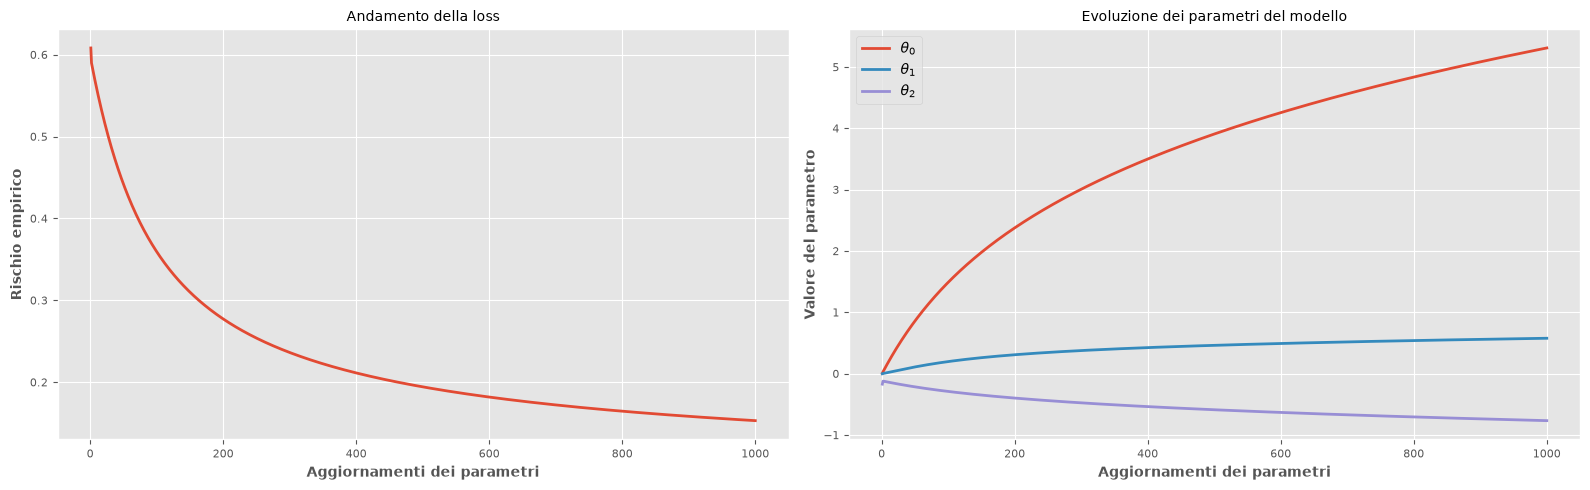

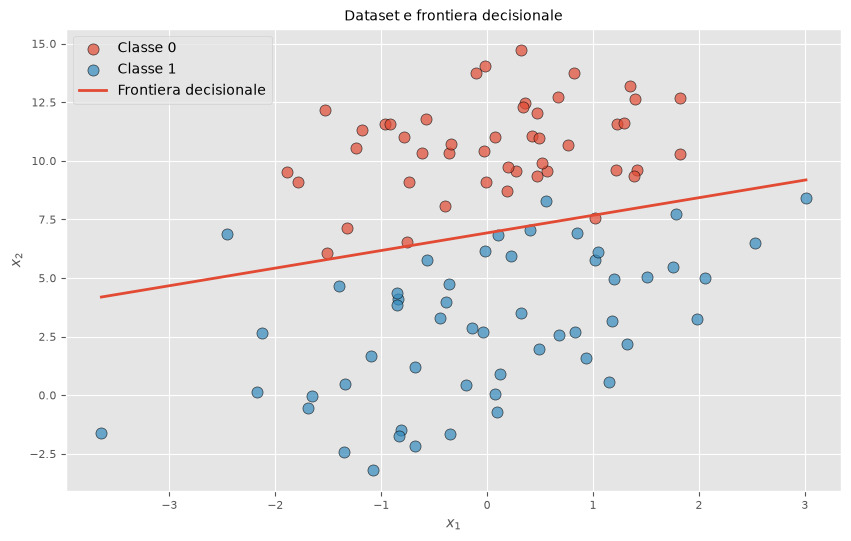

Parametri finali (Batch GD):
[ 5.30867192  0.57605434 -0.76684822]


In [12]:
# ===============================================================
# 🧩 1️⃣ Batch Gradient Descent
# ===============================================================
# In questo caso il gradiente viene calcolato su TUTTO il dataset
# a ogni iterazione (una sola volta per epoca).
# ===============================================================

epochs = 1000  # stesso numero per tutti i metodi

# ⏱️ Avvio del training
start_time = time.time()

cost_history_batch, theta_history_batch = batch_gd(
    X, t, eta=0.1, epochs=epochs
)

time_batch = time.time() - start_time

print(f"Tempo di esecuzione (Batch GD): {time_batch:.3f} s")
print(f"{len(theta_history_batch)} aggiornamenti ({epochs} epoche)")
print(f"Valore finale della loss: {cost_history_batch[-1, 0]:.4f}")

# Andamento della loss e dei parametri
plot_all(cost_history_batch, theta_history_batch)

# Frontiera decisionale finale
plot_ds(data, theta_history_batch[-1])

# Parametri appresi
print("Parametri finali (Batch GD):")
print(theta_history_batch[-1])


## Considerazioni sul Batch Gradient Descent

Il Batch Gradient Descent utilizza tutti gli esempi del training set per calcolare ogni aggiornamento.

Osservando il grafico possiamo verificare:

- se il rischio empirico diminuisce progressivamente;
- quanto rapidamente si stabilizza;
- come evolve la retta di decisione durante l'ottimizzazione.

**La discesa monotona del rischio non è garantita per qualsiasi learning rate.**

Con un learning rate opportuno e sotto adeguate condizioni di regolarità, il metodo può convergere a un minimo.

Nel nostro problema la funzione di rischio empirico della regressione logistica è **convessa** rispetto ai parametri.

Questo significa che ogni minimo locale è anche globale, se un minimo viene raggiunto.

### Vantaggi e limiti

- **Vantaggio:** ogni aggiornamento utilizza il gradiente completo del training set.
- **Limite:** ogni aggiornamento richiede un passaggio su tutti gli esempi.
- **Applicazione:** il metodo è particolarmente utile per dataset piccoli e per studiare il comportamento degli algoritmi di ottimizzazione.

Il Batch GD costituisce il riferimento con cui confronteremo SGD e Mini-Batch GD.



## Stochastic Gradient Descent (SGD)

Il **Batch Gradient Descent** calcola il gradiente utilizzando tutti gli esempi del dataset.

Lo **Stochastic Gradient Descent (SGD)** utilizza invece **un solo esempio per ogni aggiornamento**.

Per un esempio $(\mathbf{x}_i,t_i)$ della regressione logistica, la regola diventa:

$$
\theta^{(k+1)}
=
\theta^{(k)}
+
\eta(t_i-f(\mathbf{x}_i;\theta^{(k)}))\mathbf{x}_i
$$

Il gradiente del singolo esempio fornisce una stima del gradiente completo, ma introduce variabilità dovuta alla scelta del campione.

### Procedura

Per ogni epoca:

1. Mescoliamo casualmente gli esempi del dataset.
2. Selezioniamo un esempio alla volta.
3. Calcoliamo il gradiente della sua loss.
4. Aggiorniamo immediatamente i parametri.

Con $n$ esempi, **un'epoca corrisponde a $n$ aggiornamenti**.

### Comportamento atteso

- Ogni aggiornamento costa meno rispetto al Batch GD.
- Gli aggiornamenti sono più rumorosi.
- Il rischio empirico può aumentare o diminuire localmente.
- Il learning rate influenza fortemente la stabilità del metodo.

Con un learning rate costante, SGD può continuare a oscillare vicino alla soluzione.

SGD non è necessariamente più veloce in termini di tempo totale: può richiedere molti aggiornamenti per raggiungere una determinata precisione.

**Nel nostro esempio la funzione obiettivo è convessa**, quindi non abbiamo bisogno del rumore di SGD per uscire da minimi locali subottimali.


In [13]:

def stochastic_gd(X, t, eta=0.01, epochs=1000,
                  monitor_every=100, seed=42):
    """
    SGD per la regressione logistica.

    Il gradiente viene calcolato su un esempio alla volta.
    La loss completa viene calcolata soltanto per il monitoraggio.

    Returns:
        cost_history, theta_history
    """
    n, d = X.shape
    theta = np.zeros((d, 1))

    rng = np.random.default_rng(seed)

    theta_history = []
    cost_history = []

    step = 0

    for epoch in range(epochs):
        indices = rng.permutation(n)

        for i in indices:
            Xi = X[i:i+1]
            ti = t[i:i+1]

            grad_i = gradient(theta, Xi, ti)
            theta -= eta * grad_i

            step += 1

            if step % monitor_every == 0:
                theta_history.append(theta.copy())
                cost_history.append(cost(theta, X, t))

    # Salva sempre lo stato finale
    if step % monitor_every != 0:
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    theta_history = np.array(theta_history).reshape(-1, d)
    cost_history = np.array(cost_history).reshape(-1, 1)

    return cost_history, theta_history


## Applicazione dello Stochastic Gradient Descent

Tempo di esecuzione (SGD): 0.865 s
100000 aggiornamenti (1000 epoche)
100000 gradienti su singoli esempi
1000 valori della loss registrati
Valore finale della loss: 0.0974


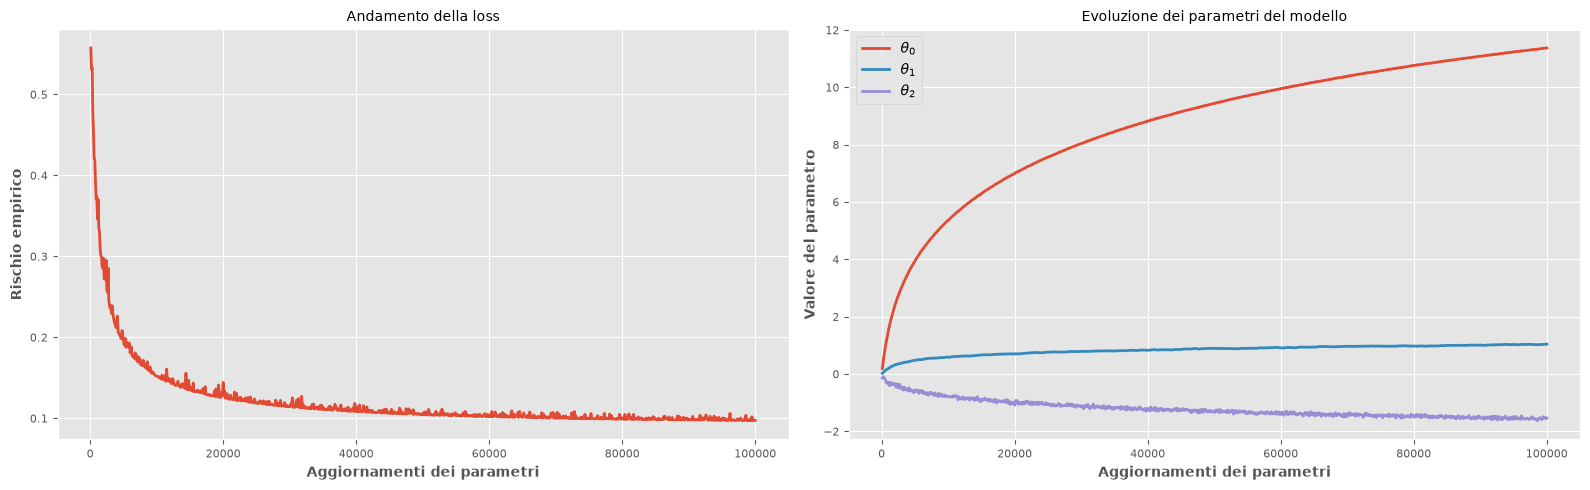

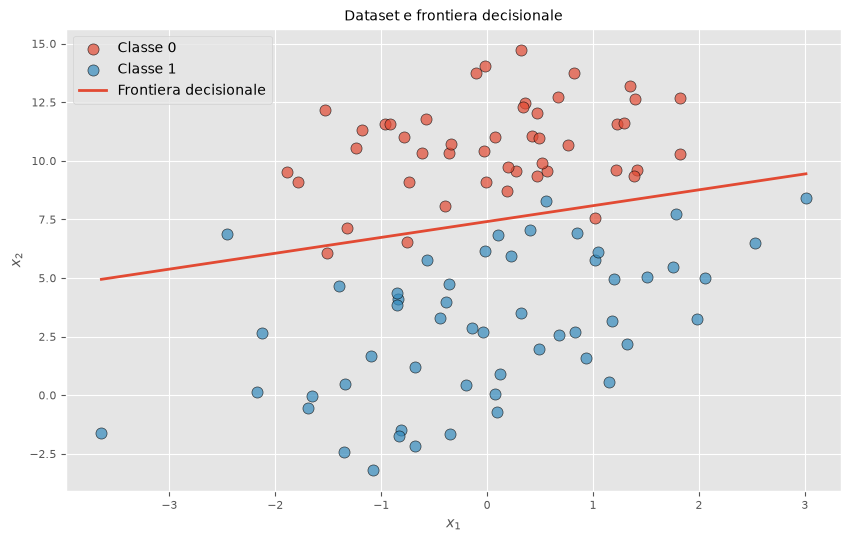

Parametri finali (SGD):
[11.3735704   1.03919719 -1.53539985]


In [14]:
# ===============================================================
# 🧩 2️⃣ Stochastic Gradient Descent (SGD)
# ===============================================================
# Qui il gradiente è calcolato su un solo campione per volta.
# Ciò comporta molti più aggiornamenti dei parametri, ma più rumorosi.
# ===============================================================

monitor_every = 100

start_time = time.time()

cost_history_sgd, theta_history_sgd = stochastic_gd(
    X, t,
    eta=0.01,
    epochs=epochs,
    monitor_every=monitor_every,
    seed=42
)

time_sgd = time.time() - start_time
updates_sgd = epochs * len(X)

print(f"Tempo di esecuzione (SGD): {time_sgd:.3f} s")
print(f"{updates_sgd} aggiornamenti ({epochs} epoche)")
print(f"{updates_sgd} gradienti su singoli esempi")
print(f"{len(cost_history_sgd)} valori della loss registrati")
print(f"Valore finale della loss: {cost_history_sgd[-1, 0]:.4f}")

# Indici degli aggiornamenti effettivamente monitorati
steps_sgd = np.arange(
    monitor_every,
    updates_sgd + 1,
    monitor_every
)

if updates_sgd % monitor_every != 0:
    steps_sgd = np.append(steps_sgd, updates_sgd)

# Rischio empirico ed evoluzione dei parametri
plot_all(cost_history_sgd, theta_history_sgd, steps=steps_sgd)

# Frontiera decisionale finale
plot_ds(data, theta_history_sgd[-1])

print("Parametri finali (SGD):")
print(theta_history_sgd[-1])



## Considerazioni sullo Stochastic Gradient Descent

Osservando l'andamento della loss possiamo valutare quanto rapidamente il metodo riduce il rischio empirico e quanto oscillano gli aggiornamenti.

Rispetto al Batch Gradient Descent:

- ogni aggiornamento utilizza meno dati;
- la traiettoria dei parametri può essere meno regolare;
- gli aggiornamenti possono essere effettuati anche quando i dati arrivano progressivamente (*online learning*).

Il comportamento dipende dal learning rate, dall'ordine degli esempi e dal numero di epoche.

Nel confronto finale terremo conto del fatto che **a parità di epoche SGD esegue molti più aggiornamenti rispetto al Batch GD**.



## Mini-Batch Gradient Descent

Il **Mini-Batch Gradient Descent (MBGD)** rappresenta un compromesso tra Batch GD e SGD.

Invece di utilizzare l'intero dataset o un singolo esempio, calcola il gradiente su piccoli gruppi di osservazioni, chiamati **mini-batch**.

Sia $B_k$ il gruppo di esempi utilizzato all'iterazione $k$, e sia $s_k$ il numero di esempi contenuti nel gruppo.

La regola generale di aggiornamento è:

$$
\theta^{(k+1)}
=
\theta^{(k)}
-
\frac{\eta}{s_k}
\sum_{i\in B_k}
\nabla_\theta L(t_i,f(\mathbf{x}_i;\theta^{(k)}))
$$

Nel caso della regressione logistica:

$$
\theta^{(k+1)}
=
\theta^{(k)}
+
\frac{\eta}{s_k}
\sum_{i\in B_k}
(t_i-f(\mathbf{x}_i;\theta^{(k)}))\mathbf{x}_i
$$

### Procedura

Per ogni epoca:

1. Mescoliamo casualmente il dataset.
2. Suddividiamo gli esempi in mini-batch.
3. Per ogni mini-batch calcoliamo il gradiente medio.
4. Aggiorniamo i parametri.

Il numero di aggiornamenti per epoca è:

$$
\left\lceil\frac{n}{s}\right\rceil
$$

dove $s$ è la dimensione massima del mini-batch. L'ultimo gruppo potrebbe contenere meno di $s$ esempi.

### Dimensione del mini-batch

- $s=1$: aggiornamenti equivalenti a quelli di SGD.
- $s=n$: aggiornamenti equivalenti a quelli di Batch GD.
- $1<s<n$: compromesso tra costo computazionale e variabilità del gradiente.

Il Mini-Batch Gradient Descent permette inoltre di sfruttare efficacemente le operazioni vettoriali e il calcolo parallelo.

Per questo è comunemente utilizzato nell'addestramento delle reti neurali.

**Non esiste però una dimensione del mini-batch ottimale per tutti i problemi:** la scelta dipende dal dataset, dal modello, dall'hardware e dal learning rate.


In [15]:
def mb_gd(X, t, eta=0.01, epochs=1000, minibatch_size=10):
    """
    Implementa il Mini-Batch Gradient Descent (MBGD) per la regressione logistica.

    A differenza del Batch GD (che usa tutto il dataset) e dello Stochastic GD
    (che usa un solo esempio per volta), qui il gradiente viene calcolato su
    piccoli gruppi di esempi ("mini-batch") di dimensione prefissata.

    Monitoraggio:
    - Anche qui, per tracciare l'andamento della funzione di costo, la 'loss'
      viene calcolata sull'INTERO dataset (X, t) e salvata in cost_history.
    - ⚠️ Attenzione: il costo globale NON viene usato per l'aggiornamento,
      serve solo a monitorare la convergenza.

    Parametri:
    ----------
    X : ndarray (n x d)
        Matrice dei dati (con colonna di 1 per il bias).
    t : ndarray (n x 1)
        Vettore delle etichette (0 o 1).
    eta : float
        Learning rate — ampiezza del passo di aggiornamento.
    epochs : int
        Numero di epoche (quante volte il dataset viene interamente attraversato).
    minibatch_size : int
        Numero di campioni usati per ogni aggiornamento dei parametri.

    Ritorna:
    --------
    cost_history : ndarray
        Valori della funzione di costo durante l’addestramento.
    theta_history : ndarray
        Valori dei parametri θ (bias + pesi) a ogni aggiornamento.
    """

    # 1️⃣ Inizializzazione
    n = len(X)                                # numero di esempi
    theta = np.zeros(X.shape[1]).reshape(-1,1) # parametri (bias + pesi)

    theta_history, cost_history = [], []
    rng = np.random.default_rng(42)

    # 2️⃣ Ciclo sulle epoche
    for _ in range(epochs):

        # Mescoliamo i dati a ogni epoca (per evitare effetti dovuti all’ordine)
        perm = rng.permutation(n)
        X_shuf, t_shuf = X[perm], t[perm]

        # 3️⃣ Ciclo sui mini-batch
        for start in range(0, n, minibatch_size):
            # Estrazione del mini-batch corrente
            Xb = X_shuf[start:start+minibatch_size]
            tb = t_shuf[start:start+minibatch_size]

            # Calcolo del gradiente sul mini-batch e aggiornamento parametri
            theta -= eta * gradient(theta, Xb, tb)

            # Salviamo i valori correnti
            theta_history.append(theta.copy())
            cost_history.append(cost(theta, X, t))  # costo sempre su tutto il dataset


    # 4️⃣ Conversione in array NumPy
    theta_history = np.array(theta_history).reshape(-1, X.shape[1])
    cost_history = np.array(cost_history).reshape(-1, 1)

    return cost_history, theta_history

Tempo di esecuzione (Mini-Batch GD): 0.242 s
10000 aggiornamenti (1000 epoche)
Valore finale della loss: 0.1529


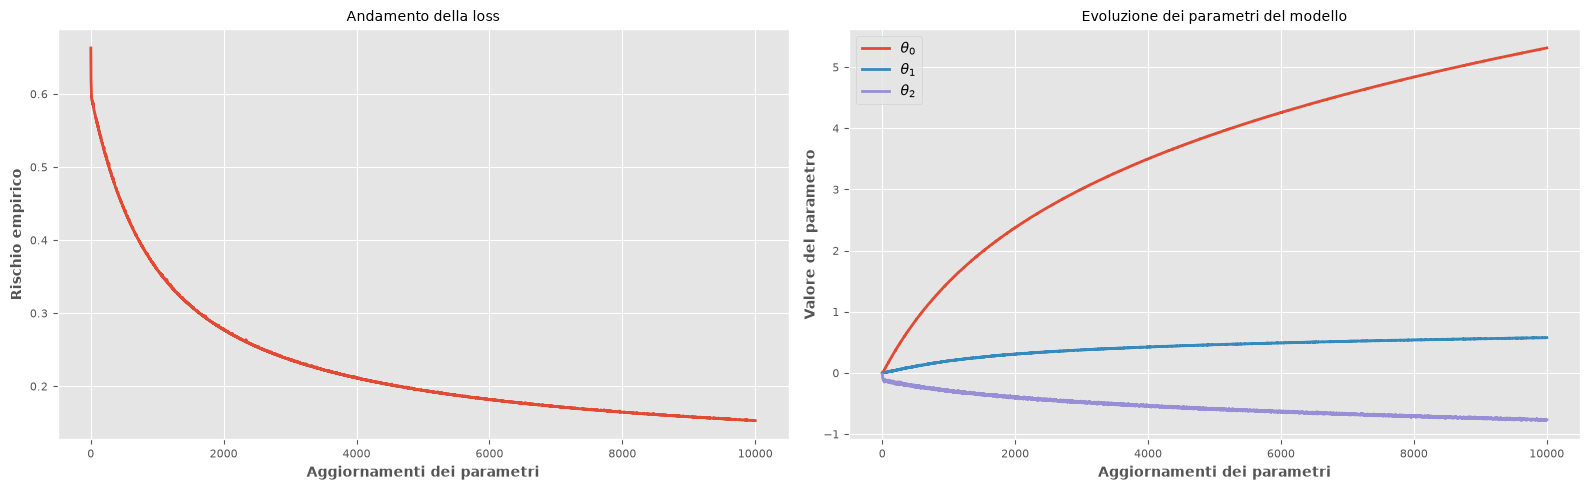

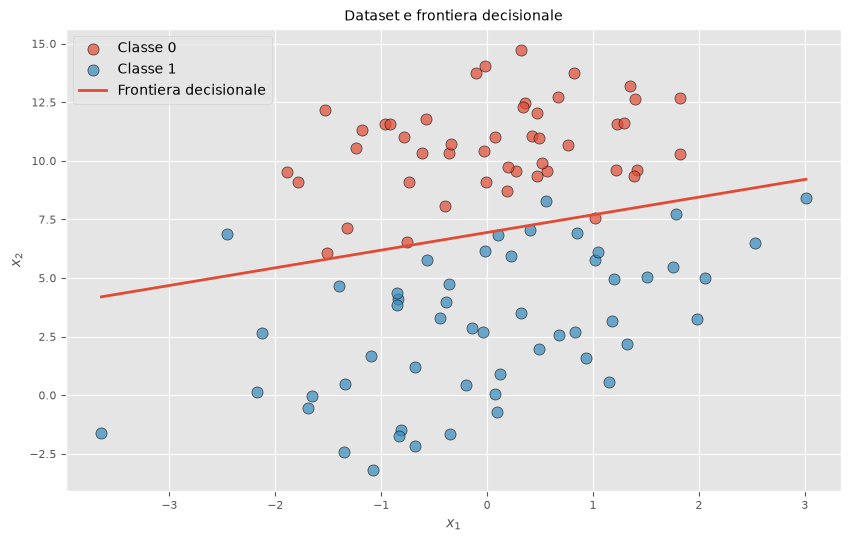

Parametri finali (Mini-Batch GD):
[ 5.3126808   0.5770797  -0.76534997]


In [16]:
# ===============================================================
# 🧩 3️⃣ Mini-Batch Gradient Descent
# ===============================================================
# Variante intermedia: il gradiente viene calcolato su piccoli
# sottoinsiemi (mini-batch) del dataset, riducendo la varianza
# e mantenendo efficienza. La dimensione del batch è fissata a 10.
# ===============================================================


minibatch_size = 10

start_time = time.time()

cost_history_mb, theta_history_mb = mb_gd(
    X, t,
    eta=0.01,
    epochs=epochs,
    minibatch_size=minibatch_size
)

time_mb = time.time() - start_time

print(f"Tempo di esecuzione (Mini-Batch GD): {time_mb:.3f} s")
print(f"{len(theta_history_mb)} aggiornamenti ({epochs} epoche)")
print(f"Valore finale della loss: {cost_history_mb[-1, 0]:.4f}")

plot_all(cost_history_mb, theta_history_mb)
plot_ds(data, theta_history_mb[-1])

print("Parametri finali (Mini-Batch GD):")
print(theta_history_mb[-1])


## Considerazioni sul Mini-Batch Gradient Descent

Il Mini-Batch Gradient Descent utilizza un sottoinsieme di esempi per ogni aggiornamento.

Rispetto a SGD, la media su più esempi tende a ridurre la variabilità del gradiente.

Rispetto a Batch GD, ogni aggiornamento richiede generalmente meno calcoli.

Osservando il grafico possiamo verificare:

- come diminuisce il rischio empirico;
- quanto oscillano gli aggiornamenti;
- come cambia la traiettoria della frontiera di decisione.

La scelta della dimensione del mini-batch influenza sia il costo computazionale sia il comportamento dell'ottimizzazione.

Non è quindi corretto affermare che un metodo sia sempre più veloce o stabile degli altri.

Il Mini-Batch GD è particolarmente interessante perché combina aggiornamenti su gruppi di esempi con l'efficienza delle operazioni vettoriali.



## Confronto dei risultati

Abbiamo addestrato lo **stesso modello di regressione logistica**, utilizzando la **stessa funzione di rischio empirico**, ma tre diverse strategie di ottimizzazione:

- Batch Gradient Descent
- Stochastic Gradient Descent
- Mini-Batch Gradient Descent

Per ogni metodo confrontiamo:

- **Epoche:** numero di passaggi completi sul dataset.
- **Updates:** numero di aggiornamenti dei parametri.
- **Samples:** numero complessivo di esempi utilizzati per il calcolo dei gradienti.
- **Loss:** valore finale del rischio empirico.
- **Time:** tempo totale di esecuzione, comprensivo delle operazioni di monitoraggio.

### Come interpretare il confronto?

I tre metodi utilizzano lo stesso numero di epoche, ma eseguono un numero differente di aggiornamenti.

Inoltre, i learning rate sono diversi e il monitoraggio della loss non ha lo stesso costo nei tre esperimenti.

**Questo confronto ha uno scopo illustrativo e non costituisce un benchmark rigoroso delle prestazioni computazionali.**

Per confrontare rigorosamente la velocità degli algoritmi sarebbe necessario controllare le condizioni sperimentali e misurare, ad esempio, il tempo necessario per raggiungere uno stesso valore della funzione obiettivo.

**Same model, same objective, different optimization strategies.**


In [17]:
# ===============================================================
# 🧩 4️⃣ Confronto finale tra i tre metodi
# ===============================================================
# Riassumiamo tempo di esecuzione, passi, gradienti calcolati
# e costo finale per evidenziare le differenze di efficienza e stabilità.
# ===============================================================
print("\n=== CONFRONTO FINALE ===")

n = len(X)

results = [
    ("Batch GD", epochs, epochs, epochs * n,
     cost_history_batch[-1, 0], time_batch),

    ("SGD", epochs, epochs * n, epochs * n,
     cost_history_sgd[-1, 0], time_sgd),

    ("Mini-Batch GD", epochs,
     epochs * int(np.ceil(n / minibatch_size)),
     epochs * n,
     cost_history_mb[-1, 0], time_mb)
]

print(f"{'Metodo':<16} {'Epoche':>8} {'Updates':>10} "
      f"{'Samples':>12} {'Loss':>10} {'Time (s)':>10}")

for method, ep, updates, samples, loss, elapsed in results:
    print(f"{method:<16} {ep:>8} {updates:>10} "
          f"{samples:>12} {loss:>10.4f} {elapsed:>10.3f}")



=== CONFRONTO FINALE ===
Metodo             Epoche    Updates      Samples       Loss   Time (s)
Batch GD             1000       1000       100000     0.1530      0.064
SGD                  1000     100000       100000     0.0974      0.865
Mini-Batch GD        1000      10000       100000     0.1529      0.242



## Dulcis in fundo: quanto bene predicono?

Abbiamo confrontato tre algoritmi di ottimizzazione osservando l'andamento della funzione di costo.

Ora vogliamo rispondere a un'altra domanda:

**I modelli ottenuti riescono a classificare correttamente gli esempi?**

Per farlo, utilizziamo i parametri stimati da ciascun algoritmo e trasformiamo le probabilità predette in etichette binarie.

Utilizziamo una soglia di decisione pari a $0.5$:

- Se la probabilità predetta è maggiore o uguale a $0.5$, assegniamo la classe 1.
- Altrimenti assegniamo la classe 0.

Misuriamo quindi l'**accuratezza**:

$$
\mathrm{Accuracy}
=
\frac{\text{Numero di predizioni corrette}}
{\text{Numero totale di esempi}}
$$


**Osservazione sulla soglia decisionale**

La soglia $0.5$ è una scelta standard per la classificazione binaria quando i costi dei due tipi di errore sono simmetrici.

In presenza di **costi asimmetrici**, come nell'esempio della pioggia, una soglia differente potrebbe minimizzare meglio il costo atteso.

La scelta della soglia dipende quindi dalla **funzione di costo del problema** e dall'affidabilità delle probabilità stimate dal modello.


### Attenzione alla generalizzazione

In questo laboratorio misuriamo l'accuratezza **sugli stessi dati utilizzati per l'addestramento**.

Questa valutazione può risultare ottimistica e non misura direttamente la capacità del modello di generalizzare a dati nuovi.

In un esperimento completo utilizzeremmo:

- un **training set** per apprendere i parametri;
- un **validation set** per selezionare gli iperparametri;
- un **test set indipendente** per valutare le prestazioni finali.

Per semplicità, in questo laboratorio confrontiamo soltanto l'accuratezza sul training set.

È inoltre importante ricordare che **minimizzare la cross-entropy non equivale direttamente a massimizzare l'accuratezza**.

La cross-entropy valuta le probabilità predette, mentre l'accuratezza valuta le classi ottenute dopo l'applicazione di una soglia.



In [18]:
# ===============================================================
# 🧮 Funzione di predizione
# ===============================================================
def predict(theta, X, thr=0.5):
    """
    Predice la classe (0/1) per ciascun campione, dati i parametri theta.

    Passaggi:
    ----------
    1. Calcola la probabilità di appartenenza alla classe positiva (t=1)
       usando la funzione sigmoide: f(x; θ) = σ(Xθ).
    2. Confronta la probabilità con la soglia 'thr' (default 0.5):
       - se >= thr → classe 1
       - altrimenti → classe 0
    3. Restituisce un vettore binario con le predizioni.

    Parametri:
    ----------
    theta : ndarray (d x 1)
        Vettore dei parametri del modello (bias + pesi).
    X : ndarray (n x d)
        Matrice dei dati (inclusa la colonna di 1 per il bias).
    thr : float
        Soglia di decisione (default = 0.5).

    Ritorna:
    --------
    y_hat : ndarray (n x 1)
        Predizioni binarie (0 o 1).
    """
    probs = f(theta, X)                  # probabilità predette
    return (probs >= thr).astype(int)    # classi predette


# ===============================================================
# 🧩 5️⃣ Confronto finale con accuratezza di classificazione
# ===============================================================
# Oltre al costo finale, valutiamo anche l'accuratezza dei modelli
# ottenuti con Batch GD, SGD e Mini-Batch.
# ===============================================================

print("\n=== 📊 ACCURATEZZA FINALE DEI MODELLI ===")
print(f"{'Metodo':<18}{'Accuratezza':<12}")

# Batch GD
theta_final_batch = theta_history_batch[-1].reshape(-1,1)
y_hat_batch = predict(theta_final_batch, X)
acc_batch = (y_hat_batch == t).mean()
print(f"{'Batch GD':<18}{acc_batch:<12.3f}")

# SGD
theta_final_sgd = theta_history_sgd[-1].reshape(-1,1)
y_hat_sgd = predict(theta_final_sgd, X)
acc_sgd = (y_hat_sgd == t).mean()
print(f"{'SGD':<18}{acc_sgd:<12.3f}")

# Mini-Batch GD
theta_final_mb = theta_history_mb[-1].reshape(-1,1)
y_hat_mb = predict(theta_final_mb, X)
acc_mb = (y_hat_mb == t).mean()
print(f"{'Mini-Batch GD':<18}{acc_mb:<12.3f}")


=== 📊 ACCURATEZZA FINALE DEI MODELLI ===
Metodo            Accuratezza 
Batch GD          0.970       
SGD               0.950       
Mini-Batch GD     0.970       


# Algoritmi avanzati di ottimizzazione

I metodi di discesa del gradiente visti finora (batch, stochastic e mini-batch) rappresentano la base dell’ottimizzazione in Machine Learning. Tuttavia, nella pratica presentano limiti significativi: lenta convergenza, sensibilità al valore del learning rate e difficoltà in presenza di funzioni di costo complesse e non convesse.  

Per affrontare queste criticità, sono stati sviluppati diversi **metodi avanzati di ottimizzazione**, che introducono strategie aggiuntive per migliorare stabilità ed efficienza della discesa:  

- **Momentum**: sfrutta l’inerzia dei passi precedenti per ridurre le oscillazioni e accelerare la convergenza.  
- **Nesterov Accelerated Gradient**: anticipa la direzione di aggiornamento, ottenendo un effetto più predittivo.  
- **Adagrad, RMSProp e Adadelta**: adattano dinamicamente il learning rate in base alla storia dei gradienti.  
- **Adam**: combina i vantaggi di momentum e adattività, diventando l’ottimizzatore più usato nelle reti neurali moderne.  
- **Metodi del secondo ordine**: sfruttano informazioni derivate dalla matrice Hessiana per una discesa più rapida e precisa.  

Nelle prossime lezioni analizzeremo questi approcci, a partire dal **metodo del momento**, per capire come affrontano i limiti delle tecniche elementari.


# 📝 Esercizi di approfondimento

In questa sezione troverai alcuni esercizi pratici per consolidare i concetti visti durante il laboratorio.  
Modifica il codice del notebook e osserva gli effetti delle tue scelte.  

---

## 1. Learning Rate

➡️ **Obiettivo:** capire come il learning rate (`eta`) influenza la convergenza.  

- Esegui il **Batch Gradient Descent** con:
  - `eta = 0.001`
  - `eta = 0.1`
  - `eta = 1.0`

📌 Domande:
1. Cosa succede al grafico della funzione di costo?
2. Come cambia il comportamento della discesa del gradiente aumentando `eta`? Un learning rate maggiore produce sempre una convergenza più rapida? Riesci a osservare oscillazioni o divergenza?

---

## 2. Numero di epoche

➡️ **Obiettivo:** osservare l’effetto del numero di iterazioni.  

- Ripeti l’esperimento con **SGD** usando:
  - `epochs = 100`
  - `epochs = 1000`
  - `epochs = 10000`

📌 Domande:
1. Come cambia la stabilità del modello?
2. La funzione di costo si stabilizza? Dopo quante epoche?

---

## 3. Dimensione del mini-batch

➡️ **Obiettivo:** confrontare vari mini-batch.  

- Prova il **Mini-Batch GD** con:
  - `minibatch_size = 1` (equivalente a SGD)
  - `minibatch_size = 10`
  - `minibatch_size = n` (equivalente a Batch GD)


**Nota:** quando `minibatch_size=1`, la regola di aggiornamento coincide con quella dello SGD. Quando `minibatch_size=n`, coincide con quella del Batch Gradient Descent.

Tuttavia, i risultati degli esperimenti possono essere diversi perché cambiano l'ordine casuale degli esempi, il learning rate e le modalità di monitoraggio.


📌 Domande:
1. Come cambia il grafico della funzione di costo?
2. Quale compromesso ti sembra migliore?

---
